In [15]:
import numpy as np
import os

from data_generator import create_params, generate_data

# Training/validation data-sets

In [16]:
D = 0.4             # Diffusivity
iterations = 100    # Total number of iterations
L = 200             # Domain length, delta_x = 1 is fixed
os.makedirs("training_data", exist_ok=True)
os.makedirs("validation_data", exist_ok=True)

### A Gaussian initialization

In [17]:
def gaussian_func(x, mu, sigma):
    return 1 / np.sqrt(2 * np.pi * sigma**2) * np.exp(
        -(x - mu)**2 / (2 * sigma**2)
    )

In [18]:
params_dict = {
    "mu": (-L/4, L/4, 5),
    "sigma": (2, 12, 6)
}
params = create_params(params_dict)
training_range = (0, 10)
validation_range = (60, 61)
training_data, validation_data = generate_data(
    gaussian_func,
    params,
    D,
    L,
    iterations,
    training_range,
    validation_range
)
print("Parameters shape: ", params.shape)
print("Training data shape: ", training_data.input.shape)
print("Validation data shape: ", validation_data.input.shape)

Parameters shape:  (30, 2)
Training data shape:  (330, 201)
Validation data shape:  (60, 201)


In [19]:
np.savez(
    "training_data/gaussian.npz",
    input=training_data.input,
    output=training_data.output
)
np.savez(
    "validation_data/gaussian.npz",
    input=validation_data.input,
    output=validation_data.output
)

### A uniform block initialization

In [20]:
def uniform_func(x, mu, l):
    return np.where(np.abs(x - mu) < l/2, 1/l, 0)

In [21]:
params_dict = {
    "mu": (-L/4, L/4, 5),
    "l": (L/16, L/4, 5),
}
params = create_params(params_dict)
training_range = (0, 10)
validation_range = (60, 61)
training_data, validation_data = generate_data(
    uniform_func,
    params,
    D,
    L,
    iterations,
    training_range,
    validation_range
)
print("Parameters shape: ", params.shape)
print("Training data shape: ", training_data.input.shape)
print("Validation data shape: ", validation_data.input.shape)

Parameters shape:  (25, 2)
Training data shape:  (275, 201)
Validation data shape:  (50, 201)


In [22]:
np.savez(
    "training_data/uniform.npz",
    input=training_data.input,
    output=training_data.output
)
np.savez(
    "validation_data/uniform.npz",
    input=validation_data.input,
    output=validation_data.output
)

### A cosine initialization

In [23]:
def cosine_func(x, mu, l, n):
    return np.where(np.abs(x - mu) < l/2, np.cos(n * np.pi * (x - mu) / l), 0)

In [24]:
params_dict = {
    "mu": (-L/4, L/4, 5),
    "l": (L/16, L/4, 5),
    "n": (1, 5, 5)
}
params = create_params(params_dict)
training_range = (0, 10)
validation_range = (60, 61)
training_data, validation_data = generate_data(
    cosine_func,
    params,
    D,
    L,
    iterations,
    training_range,
    validation_range
)
print("Parameters shape: ", params.shape)
print("Training data shape: ", training_data.input.shape)
print("Validation data shape: ", validation_data.input.shape)

Parameters shape:  (125, 3)
Training data shape:  (1375, 201)
Validation data shape:  (250, 201)


In [25]:
np.savez(
    "training_data/cosine.npz",
    input=training_data.input,
    output=training_data.output
)
np.savez(
    "validation_data/cosine.npz",
    input=validation_data.input,
    output=validation_data.output
)

# Auto-regressive testing data

In [26]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from fdm_solver import State

In [27]:
def plot_solution(state):
    colors = ["red", "blue", "green", "orange"]
    fig = plt.figure(2)
    ax = fig.add_axes([0.20, 0.18, 0.79, 0.81])
    ax.plot(state.x / L, state.u_initial, linewidth=2, color="black",
            linestyle="solid", label=r"t = 0", zorder=1)
    for itr, t in enumerate([10, 20, 50, 100]):
        ax.plot(state.x / state.L, state.u[t], linewidth=2,
                color=colors[itr], linestyle="solid",
                label=r"t = " + str(t), zorder=1)
    ax.set_xlabel(r"$x / L$", fontsize=18)
    ax.set_ylabel(r"$u$", fontsize=18)
    ax.set_xlim(-0.5, 0.5)
    ax.set_xticks([-0.5, -0.25, 0, 0.25, 0.5])
    ax.set_xticklabels([-0.5, -0.25, 0, 0.25, 0.5])
    ax.tick_params(axis="both", labelsize=14)
    ax.yaxis.set_major_locator(MaxNLocator(nbins=6))
    ax.legend(loc="best", frameon=False, fontsize=14)
    plt.show()
    plt.close()

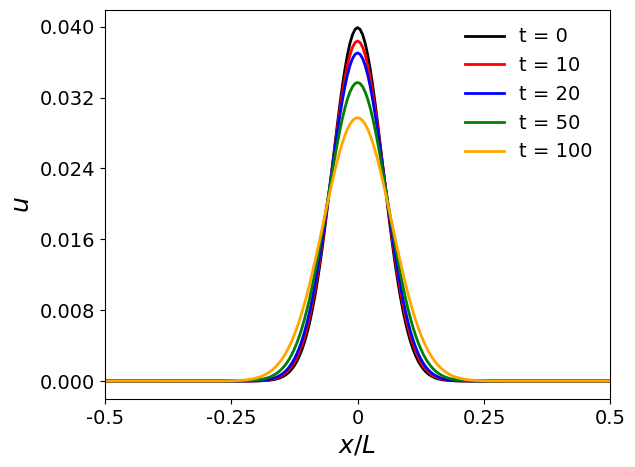

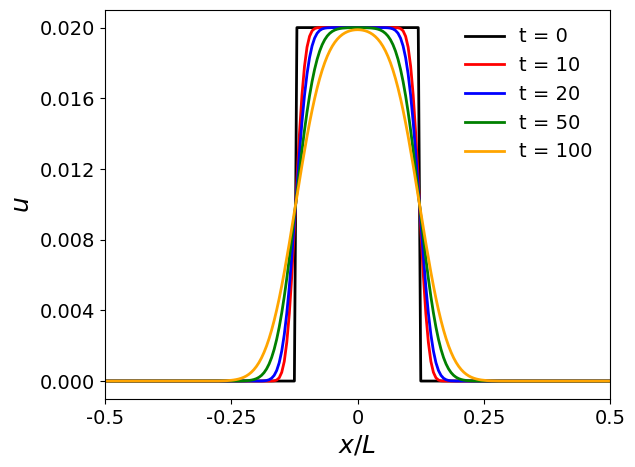

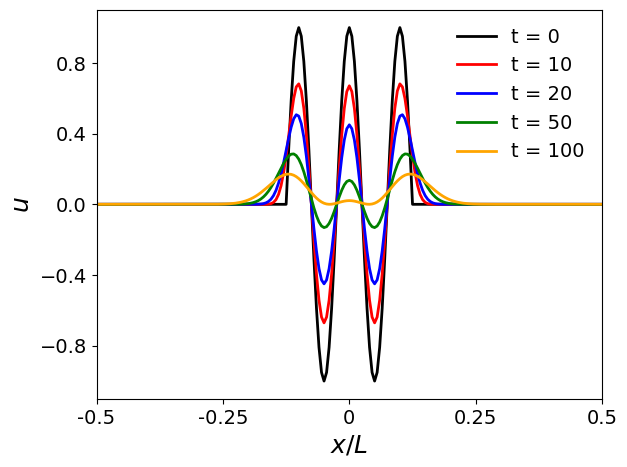

In [28]:
os.makedirs("testing_data", exist_ok=True)
params = {
    "gaussian": (0, 10),
    "uniform": (0, L/4),
    "cosine": (0, L/4, 5)
}
for case_name in ["gaussian", "uniform", "cosine"]:
    state = State(L)
    state.initialize(
        globals().get(case_name + "_func"),
        params[case_name]
    )
    state.evolve(iterations, D, verbose=False)
    plot_solution(state)
    np.savez(
        "testing_data/" + case_name + ".npz",
        u=state.u,
        params=np.array(params[case_name]),
        Nx=state.u.shape[1],
        snaps=state.u.shape[0]
    )